## Interval Analysis

In [1]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


100%|██████████| 9.91M/9.91M [00:00<00:00, 44.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.16MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.53MB/s]


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [2]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

### Write the interval analysis for the simple model

In [3]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012
Epoch 2/15, Loss: 1.729
Epoch 3/15, Loss: 1.627
Epoch 4/15, Loss: 1.596
Epoch 5/15, Loss: 1.582
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.550
Epoch 12/15, Loss: 1.547
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.542
Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


In [4]:
# Weights
model.eval()
W1 = model[1].fc.weight.data
b1 = model[1].fc.bias.data
W2 = model[1].fc2.weight.data
b2 = model[1].fc2.bias.data

# The output layer
W_out = []
b_out = []
for label in range(10):
    W = torch.zeros(10, 200)
    b = torch.zeros(10)
    for j in range(10):
        W[j] = W2[label] - W2[j]
        b[j] = b2[label] - b2[j]
    W_out.append(W)
    b_out.append(b)

In [5]:
# Box transformers

# Affine layer
def affine_bounds(l, u, W, b):
    products_l = W * l
    products_u = W * u
    lower_terms = torch.minimum(products_l, products_u)
    upper_terms = torch.maximum(products_l, products_u)
    new_l = lower_terms.sum(dim=1) + b
    new_u = upper_terms.sum(dim=1) + b
    return new_l, new_u

# ReLU
def relu_bounds(l, u):
    return torch.relu(l), torch.relu(u)

In [6]:
# Interval analysis

def lower_bounds(x, y, eps):
    l = torch.clamp(x - eps, 0, 1).flatten()
    u = torch.clamp(x + eps, 0, 1).flatten()

    l = model[0](l)
    u = model[0](u)
    # Layer 1 and ReLU
    l, u = affine_bounds(l, u, W1, b1)
    l, u = relu_bounds(l, u)
    # Layer 2 merged with the output layer for label y
    l, u = affine_bounds(l, u, W_out[y], b_out[y])
    return l

In [7]:
epsilons = np.linspace(0.01, 0.1, 10)
accuracies = []
for eps in epsilons:
    count = 0
    for x, y in test_dataset:
        if lower_bounds(x, y, eps).min() >= 0:
            count += 1
    accuracies.append(100 * count / len(test_dataset))
    print("eps:", round(eps, 2), "verified accuracy:", accuracies[-1])

eps: 0.01 verified accuracy: 70.55
eps: 0.02 verified accuracy: 23.68
eps: 0.03 verified accuracy: 4.56
eps: 0.04 verified accuracy: 0.58
eps: 0.05 verified accuracy: 0.02
eps: 0.06 verified accuracy: 0.0
eps: 0.07 verified accuracy: 0.0
eps: 0.08 verified accuracy: 0.0
eps: 0.09 verified accuracy: 0.0
eps: 0.1 verified accuracy: 0.0


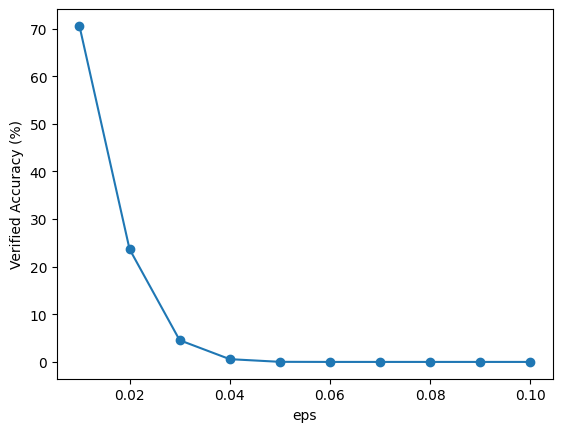

In [8]:
# Step 7: plot the verified accuracy against eps
plt.plot(epsilons, accuracies, marker="o")    # marker="o" draws a dot at each of the 10 points
plt.xlabel("eps")
plt.ylabel("Verified Accuracy (%)")
plt.show()

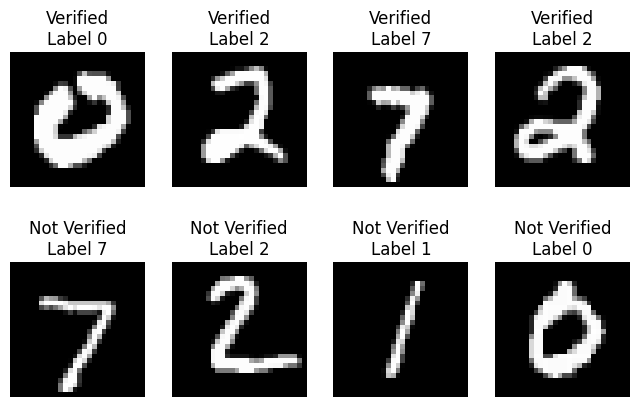

In [9]:
eps = 0.03
verified_images = []
verified_labels = []
not_verified_images = []
not_verified_labels = []
for x, y in test_dataset:
    if lower_bounds(x, y, eps).min() >= 0:
        if len(verified_images) < 4:
            verified_images.append(x[0])
            verified_labels.append(y)
    else:
        if len(not_verified_images) < 4:
            not_verified_images.append(x[0])
            not_verified_labels.append(y)
    if len(verified_images) == 4 and len(not_verified_images) == 4:
        break

plt.figure(figsize=(8, 5))
for k in range(4):
    plt.subplot(2, 4, k + 1)
    plt.imshow(verified_images[k], cmap="gray")
    plt.title("Verified\nLabel " + str(verified_labels[k]))
    plt.axis("off")
    plt.subplot(2, 4, k + 5)
    plt.imshow(not_verified_images[k], cmap="gray")
    plt.title("Not Verified\nLabel " + str(not_verified_labels[k]))
    plt.axis("off")
plt.show()